# Regresión lineal y regularización

La regresión lineal es el punto de partida de casi todo el aprendizaje supervisado. Supone que la respuesta es una combinación lineal de los predictores más un error:

$$y = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p + \varepsilon.$$

Es simple, rápida, interpretable y, aunque la relación real casi nunca sea exactamente lineal, suele ser una buena aproximación. Además, muchos métodos más complejos son extensiones suyas {cite}`james2021,gelman2007`.

## Estimación por mínimos cuadrados

Los coeficientes se estiman por mínimos cuadrados ordinarios (MCO), minimizando la suma de los cuadrados de los residuos; la solución es la ecuación normal $\hat\beta = (X^TX)^{-1}X^Ty$ (capítulo {doc}`09_Optimizacion`). Si los errores son normales, MCO coincide con el estimador de máxima verosimilitud. Cada coeficiente se interpreta como el cambio esperado en $y$ por un aumento de una unidad en su predictor, manteniendo los demás constantes. El intercepto es el valor esperado de $y$ cuando todos los predictores valen cero; muchas veces no tiene sentido físico, pero casi siempre debe incluirse, porque absorbe el sesgo que no explican los demás términos. La significancia de cada coeficiente se evalúa con su estadístico t, el coeficiente dividido por su error estándar; su valor absoluto es también una medida de la importancia de la variable.

Como ejemplo se simula la resistencia a la compresión uniaxial (UCS) de muestras de roca en función de la porosidad, la velocidad de onda P y la densidad, con una relación conocida.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(9)

n = 120
por = rng.uniform(2, 25, n)                                  # %
vp = 6.2 - 0.12 * por + rng.normal(0, 0.25, n)                # km/s, correlacionada con la porosidad
dens = 2.75 - 0.018 * por + rng.normal(0, 0.03, n)            # g/cm³, también correlacionada
ucs = 40 + 18 * vp - 2.2 * por + rng.normal(0, 8, n)          # MPa

def mco(X, y, nombres):
    Xd = np.column_stack([np.ones(len(y)), X])
    b = np.linalg.solve(Xd.T @ Xd, Xd.T @ y)
    res = y - Xd @ b
    gl = len(y) - Xd.shape[1]
    s2 = res @ res / gl
    se = np.sqrt(np.diag(s2 * np.linalg.inv(Xd.T @ Xd)))
    t = b / se; p = 2 * stats.t.sf(np.abs(t), gl)
    r2 = 1 - res @ res / np.sum((y - y.mean())**2)
    print(f'{"":12s} {"coef":>8s} {"err.est.":>8s} {"t":>7s} {"p":>9s}')
    for nm, bi, si, ti, pi in zip(['intercepto'] + nombres, b, se, t, p):
        print(f'{nm:12s} {bi:8.2f} {si:8.2f} {ti:7.2f} {pi:9.2g}')
    print(f'R² = {r2:.3f}   R² ajustado = {1 - (1 - r2) * (len(y) - 1) / gl:.3f}   error estándar residual = {np.sqrt(s2):.2f} MPa')
    return b, res, Xd @ b

print('Modelo con las tres variables:')
b, res, ajust = mco(np.column_stack([por, vp, dens]), ucs, ['porosidad', 'Vp', 'densidad'])

Modelo con las tres variables:
                 coef err.est.       t         p
intercepto     177.81    73.60    2.42     0.017
porosidad       -3.25     0.64   -5.07   1.5e-06
Vp              17.43     3.29    5.30   5.6e-07
densidad       -48.29    25.00   -1.93     0.056
R² = 0.931   R² ajustado = 0.930   error estándar residual = 8.41 MPa


## Supuestos y diagnóstico

La inferencia sobre los coeficientes descansa en varios supuestos: relación lineal entre la respuesta y los predictores; residuos con distribución normal; varianza constante de los residuos (homocedasticidad); ausencia de autocorrelación en los residuos, que en geociencias suele romperse con datos espaciales o temporales; y ausencia de multicolinealidad fuerte entre predictores. Se revisan con gráficas de los residuos: contra los valores ajustados, para ver tendencias o embudos; un gráfico QQ, para la normalidad; y contra cada predictor o contra las coordenadas, para ver estructura no capturada.

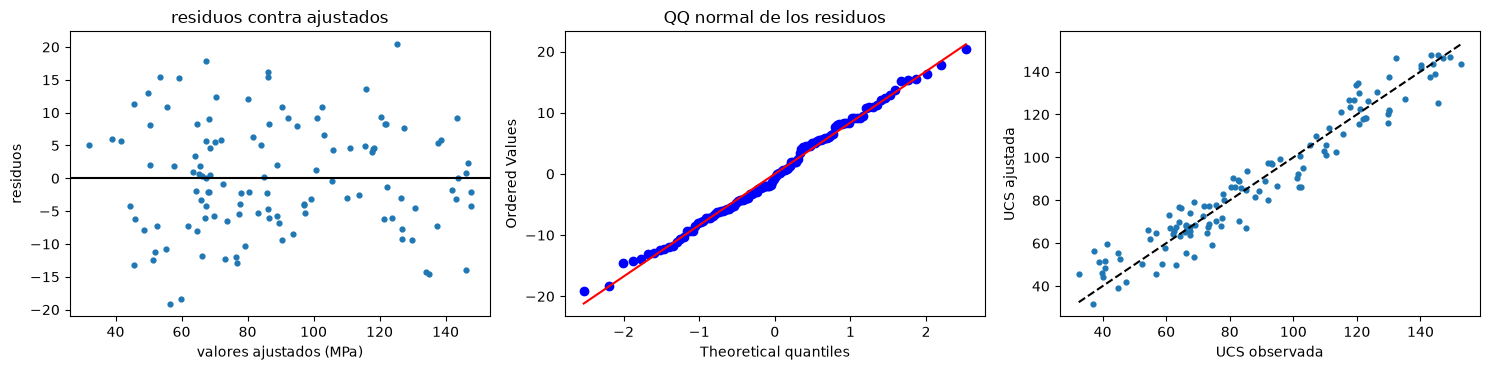

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].scatter(ajust, res, s=12); axs[0].axhline(0, color='k'); axs[0].set_xlabel('valores ajustados (MPa)'); axs[0].set_ylabel('residuos'); axs[0].set_title('residuos contra ajustados')
stats.probplot(res, plot=axs[1]); axs[1].set_title('QQ normal de los residuos')
axs[2].scatter(ucs, ajust, s=12); axs[2].plot([ucs.min(), ucs.max()], [ucs.min(), ucs.max()], 'k--'); axs[2].set_xlabel('UCS observada'); axs[2].set_ylabel('UCS ajustada')
plt.tight_layout(); plt.show()

## Multicolinealidad

La porosidad, la velocidad de onda P y la densidad están muy correlacionadas. La multicolinealidad no afecta las predicciones, pero infla los errores estándar de los coeficientes, puede volverlos no significativos o cambiarles el signo, y hace inestable la interpretación. En la tabla anterior la densidad, que no interviene en la relación verdadera, puede aparecer con un coeficiente grande e incierto. El factor de inflación de la varianza (capítulo {doc}`08_SeleccionVariables`) lo cuantifica; las soluciones son eliminar variables redundantes, combinarlas o usar regularización.

In [3]:
Z = np.corrcoef(np.column_stack([por, vp, dens]), rowvar=False)
print('VIF:', {k: round(float(v), 1) for k, v in zip(['porosidad', 'Vp', 'densidad'], np.diag(np.linalg.inv(Z)))})
print('\nModelo sin la densidad:')
_ = mco(np.column_stack([por, vp]), ucs, ['porosidad', 'Vp'])

VIF: {'porosidad': 30.0, 'Vp': 13.4, 'densidad': 14.9}

Modelo sin la densidad:
                 coef err.est.       t         p
intercepto      41.32    20.84    1.98      0.05
porosidad       -2.32     0.43   -5.40   3.6e-07
Vp              18.08     3.31    5.46   2.7e-07
R² = 0.929   R² ajustado = 0.928   error estándar residual = 8.50 MPa


## Interacciones y no linealidad

El modelo lineal puede capturar relaciones no lineales y efectos combinados transformando los predictores. Un término polinómico, como $x^2$, permite curvatura; un logaritmo lineariza relaciones multiplicativas (los coeficientes de un modelo en logaritmos se interpretan como cambios porcentuales); y un término de interacción $x_1 x_2$ permite que el efecto de $x_1$ dependa del valor de $x_2$. Cuando se incluye una interacción, el modelo debe incluir también los términos individuales que la forman, y conviene centrar las variables para reducir la colinealidad entre ellos.

## Regularización: ridge y lasso

Con muchos predictores, o predictores correlacionados, los coeficientes de MCO tienen varianza alta. La regularización agrega a la función de costo una penalización por la magnitud de los coeficientes, controlada por un parámetro $\lambda$ que se elige por validación cruzada. Ridge penaliza la suma de los cuadrados (norma L2) y encoge todos los coeficientes hacia cero sin anularlos; reparte el peso entre variables correlacionadas. Lasso {cite}`tibshirani1996` penaliza la suma de los valores absolutos (norma L1) y anula algunos coeficientes, de modo que también selecciona variables. Elastic net combina las dos. Al aumentar $\lambda$ se reduce la varianza a costa de aumentar el sesgo; el valor óptimo equilibra ambos. Las variables deben estandarizarse antes de regularizar, para que la penalización las trate por igual.

La celda siguiente compara MCO, ridge y lasso en un caso con 40 predictores, de los cuales solo 5 son relevantes, y apenas 60 observaciones.

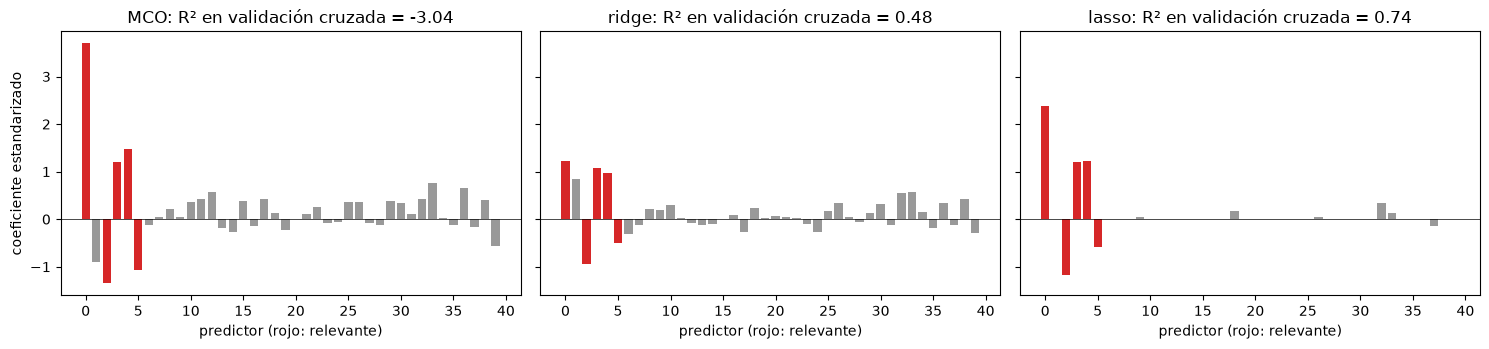

In [4]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

n, p = 60, 40
Xr = rng.normal(0, 1, (n, p))
Xr[:, 1] = Xr[:, 0] + rng.normal(0, 0.3, n)                   # dos predictores correlacionados
beta = np.zeros(p); beta[[0, 2, 3, 4, 5]] = [3, -2, 1.5, 1, -1]
yr = Xr @ beta + rng.normal(0, 2, n)
modelos = {'MCO': LinearRegression(), 'ridge': RidgeCV(alphas=np.logspace(-2, 3, 50)), 'lasso': LassoCV(cv=5, random_state=0, max_iter=20000)}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, (nom, m) in zip(axs, modelos.items()):
    pipe = make_pipeline(StandardScaler(), m)
    r2 = cross_val_score(pipe, Xr, yr, cv=5, scoring='r2').mean()
    coef = pipe.fit(Xr, yr)[-1].coef_
    ax.bar(range(p), coef, color=['tab:red' if b != 0 else '0.6' for b in beta]); ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{nom}: R² en validación cruzada = {r2:.2f}'); ax.set_xlabel('predictor (rojo: relevante)')
axs[0].set_ylabel('coeficiente estandarizado')
plt.tight_layout(); plt.show()

MCO, con casi tantas variables como datos, asigna coeficientes grandes a variables de ruido y predice mal en validación. Ridge los encoge y mejora mucho la predicción. Lasso además anula la mayoría de los coeficientes irrelevantes y recupera casi exactamente el conjunto de variables verdaderas.

## Para profundizar

Los capítulos 3 y 6 de {cite}`james2021` desarrollan la regresión lineal y la regularización, y los capítulos 3 a 5 de {cite}`gelman2007`, la interpretación y el diagnóstico. El notebook 15 del curso explica la salida completa de `statsmodels` (pruebas ómnibus, Durbin-Watson, Jarque-Bera, número de condición) con datos reales.